# 04. Смешанная модель в somer


In [1]:
knitr::opts_chunk$set(
  echo = TRUE,
  message = FALSE,
  warning = FALSE,
  fig.width = 9,
  fig.height = 5
)


In [2]:
fix_categorical_effects = c('event_season', 'event_year', 'economy')
fix_numerical_effects = c('okot_number', 'okot_massa', 'okot_vsego', 'dam_age', 'sire_age')


---
title: "04. Смешанная модель в somer"
date: "`Sys.Date()`"
output:
  html_document:
    toc: true
    toc_depth: 3
    toc_float:
      collapsed: false
    theme: flatly
    highlight: tango
    df_print: paged
---


# О документе

Отчёт считает ту же ssGBLUP-модель пакетом **sommer** (`mmes`), без ручной сборки X и Z.

| | |
|---|---|
| **Данные** | `data/pedigree.csv`, `data/phenotypes.csv`, `data/genotypes.csv` |
| **Цель** | Задать животное через `vsm(ism(animal), Gu = H)` и хозяйство как случайный эффект |
| **Результат** | EBV, SE и reliability из `mmes` |


In [3]:
library(rrBLUP)
library(AGHmatrix)
library(pedigreeTools)
library(sommer)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)


Loading required package: Matrix


Loading required package: MASS


Loading required package: crayon



Attaching package: ‘sommer’



The following objects are masked from ‘package:rrBLUP’:

    A.mat, GWAS




Attaching package: ‘dplyr’



... (3 outputs left out)


Attaching package: ‘ggplot2’



The following object is masked from ‘package:crayon’:

    %+%




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



# Вступление

Оценка племенной ценности методом BLUP (Best Linear Unbiased Prediction) является стандартом в генетике животных. Несмотря на широкое распространение специализированного програмного обеспечения, такого как семейство программ BLUPF90, в некоторых случаях может быть целесообразно реализовать расчёт вручную с помощью языка R. Это позволяет получить полный контроль над моделью, гибко адаптировать структуру данных, визуализировать промежуточные шаги и глубже понять математическую сущность модели.

Преимущества расчёта в среде R по сравнению с расчётом с помощью программы BLUPF90:

- Гибкость в модели. Возможность свободно варьировать структуру фиксированных и случаёных эффектов;

- Прозрачность алгоритма. Все необходимые матрицы создаются вручную. Мы видим, что происходит;

- Визуализация и диагностика. Можно сделать любую визуализацию на каждом этапе;

- Удобная отладка. При ошибке можно локализовать этап, где возникла проблема;

- Возможность включения новых алгоритмов. Можно добавить любой алгоритм, который повысит точность полученной оценки.

В данной работе была применена смешанная линейная модель (Mixed Linear Model) для оценки племенной ценности животных методом BLUP. Смешанные модели представляют собой расширение классических линейных моделей, позволяющие одновременно оценивать как животных с предками и потомством, так и без них, как генотипированных особей, так и негенотипированных. Использование смешанных моделей в генетике животных позволяет даёт возможность корректно оценить генетическую ценность особей даже при наличии неравного количества потомков, разного количества данных и сложных структур популяции. 

# 1. Загрузка данных

В первую очередь необходимо загрузить необходимые нам данные: 

- Данные родословной;

- Фенотипические данные;

- Данные по SNP-маркерам у генотипированных животных. 

Это обязательные данные для расчёта качественной оценки. Кроме того, нам будет необходим список всех животных, которые каким бы то ни было образом присутствуют в наших данных: это животные, по которым у нас есть фенотипические данные, генетические данные и сведения в родословной - как самого животного, так и его родителей. Согласно этому списку каждому животному будет присвоен номер.

Таблицы читаются из CSV, заранее сохранённых скриптом `tools/generate_data.R`.


In [4]:
phenotypes <- read.csv('data/phenotypes.csv') %>%
  dplyr::select(animal, dam_age, sire_age, okot_number, okot_massa, okot_vsego, event_season, event_year, economy, trait)
genotypes <- read.csv('data/genotypes.csv', colClasses = c(nom_osn = 'character', gen = 'character'))
pedigree <- read.csv('data/pedigree.csv')
animals <- na.omit(unique(c(phenotypes$animal, genotypes$nom_osn, pedigree$animal, pedigree$dam, pedigree$sire)))
common_levels <- levels(as.factor(animals))


In [5]:
all_levels <- c("Intercept", unique(phenotypes$event_year), unique(phenotypes$event_season), unique(phenotypes$economy), fix_categorical_effects, fix_numerical_effects)


In [6]:
print(knitr::kable(head(pedigree, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))
print(knitr::kable(head(genotypes %>% mutate(gen = str_trunc(gen, width = 25)), 5), booktabs=TRUE, caption='Данные генетики (фрагмент)'))




Table: Данные родословной (фрагмент)

| animal| sire| dam|
|------:|----:|---:|
|      1|    0|   0|
|      2|    0|   0|
|      3|    0|   0|
|      4|    0|   0|
|      5|    0|   0|




Table: Данные фенотипов (фрагмент)

| animal|    dam_age|   sire_age| okot_number| okot_massa| okot_vsego|event_season | event_year|economy |      trait|
|------:|----------:|----------:|-----------:|----------:|----------:|:------------|----------:|:-------|----------:|
|      1| -0.5293859|  0.5743562|   0.6679681|  0.0908113|  0.0076706|summer       |       2022|farm4   |  0.8189411|
|      2| -0.4707870| -0.2307000|  -0.0131677|  0.2626232|  0.5241680|spring       |       2023|farm4   |  3.4704416|
|      3| -1.5459369|  1.1722425|   0.7760470|  0.0693349|  1.3263359|spring       |       2023|farm2   | -0.9278001|
|      4| -0.0405267|  1.3927027|  -2.0107353| -0.5286438| -0.1135677|autumn       |       2024|farm2   | -0.2795238|
|      5|  0.8903563| -0.6619913|  -1.1281805| -0.1302022|  1.5991495|spring       |       2022|farm2   | -0.4406823|




Table: Данные генетики (фрагмент)

|nom_osn |gen                       |
|:-------|:-------------------------|
|121     |1011011010010201101001... |
|122     |2112110001111200010010... |
|123     |1110000001121101101000... |
|124     |1001221120111201000000... |
|125     |0000101100010011000010... |


Теперь, когда у нас есть все необходимые нам данные, мы можем приступать к их преобразованию для дальнейшей работы с ними.

# 2. Преобразование загруженных данных

Преобразование данных является неотъемлемой частью работы. Нам их необходимо преобразовать так, чтобы в дальнейшем их использовать для подачи в матрицы. С помощью этих матриц мы и будем рассчитывать оценки племенной ценности.

## 2.1. Проверка данных фенотипов на выбросы и аномалии

Мы начинаем преобразование данных с проверки данных фенотипов (переменной трейт) на выбросы. Для этого нам необходим Z-score порог.

Z-score порог - это значение Z-score, которое используется для идентификации выбросов или необычных наблюдений в данных. Он играет роль границы и квалифицирует наблюдение как аномальное. Он рассчитывается по следующей формуле:

$$
Z = \frac{{X - \mu}}{{\sigma}}
$$
Где:
- $X$ — отдельное наблюдение,
- $\mu$ — среднее значение массива,
- $\sigma$ — стандартное отклонение массива

Для проверки качества отфильтрованного массива мы будем использовать две переменные:

1. Ассиметрия (skewness) - это мера ассиметрии распределения относительно его среднего значения;

2. Эксцесс (kurtosis) - характеристика толщины хвостов и "заострения" пика распределения

Мы должны подобрать такой Z-score, чтобы ассиметрия и эксцесс были наиболее близки к 0.


In [7]:
# Z-score filter
z_score_filter <- function(pipeline, threshold) {
  array <- na.omit(pipeline$trait)
  mean_array <- mean(pipeline$trait)
  sd_array <- sd(pipeline$trait)
  z_scores <- abs((pipeline$trait - mean_array) / sd_array)
  outliers <- pipeline$trait[z_scores > threshold]
  pipeline <- pipeline %>%
    filter(!(trait %in% outliers))
  print(paste('Skewness =', skewness(pipeline$trait)))
  print(paste('Kurtosis =', kurtosis(pipeline$trait)))
  print(qqplot_distribution(pipeline$trait, 'trait'))
  return(pipeline)
}

qqplot_distribution <- function(array, name) {
  qqnorm(array,
         main=paste('QQPlot распределения переменной', name, sep=' '),
         xlab='Теоретические квантили',
         ylab='Квантили массива')
  qqline(array,
         col='red')
}


[1] "Skewness = -0.0623451157568916"
[1] "Kurtosis = -0.246800594106129"


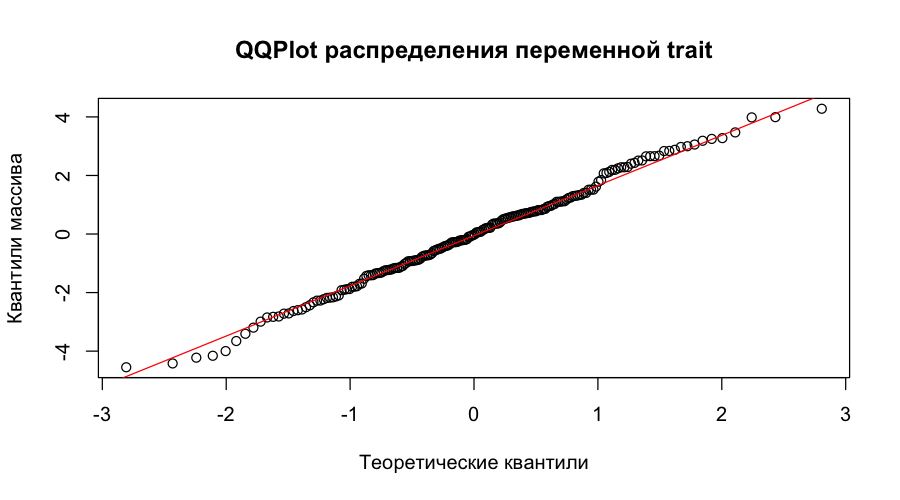

NULL


In [8]:
phenotypes <- z_score_filter(phenotypes, 3.1)


После того, как мы нашли оптимальное значение Z-score, мы получили необходимое качество данных для следующих преобразований.

## 2.2. Преобразование данных родословной, генетики и фенотипов

В первую очередь, нам важно:

1. Синхронизировать наши данные по родословной - оставить только тех животных в родословной, которые присутствуют в фенотипах как сами животные или как предки;

2. Заменить ID животного, которое было у нас изначально из данных, на номер, который мы получили согласно полному списку животных. С номером будет намного проще и удобнее строить матрицы, чем с использованием ID;

3. Всем колонкам присвоить определённые типы: 

- колонки с номерами животных получают тип **integer**; 

- колонки с нумерованными эффектами получают тип **numeric**; 

- колонки с категориальными эффектами получают тип **factor**. 

Такая чёткая градация необходима для дальнейшего расчёта оценок.


In [9]:
pedigree_bl <- pedigree %>%
  filter((animal %in% phenotypes$animal) | (dam %in% phenotypes$animal) | (sire %in% phenotypes$animal)) %>%
  mutate(across(c(animal, dam, sire), ~as.integer(factor(., levels = common_levels))))
genotypes_bl <- genotypes %>%
  mutate(nom_osn = as.integer(factor(nom_osn, levels=common_levels)))
phenotypes_bl <- phenotypes %>%
  mutate(animal = as.integer(factor(animal, levels=common_levels))) %>%
  mutate(across(all_of(fix_categorical_effects), ~factor(.x))) %>%
  mutate(across(all_of(fix_numerical_effects), ~as.numeric(.x)))
animals_bl <- na.omit(unique(c(phenotypes_bl$animal, genotypes_bl$nom_osn, pedigree_bl$animal, pedigree_bl$dam, pedigree_bl$sire)))


In [10]:
print(knitr::kable(head(pedigree_bl, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes_bl, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))
print(knitr::kable(head(genotypes_bl %>% mutate(gen = str_trunc(gen, width = 25)), 5), booktabs=TRUE, caption='Данные генетики (фрагмент)'))




Table: Данные родословной (фрагмент)

| animal| sire| dam|
|------:|----:|---:|
|      2|    1|   1|
|    113|    1|   1|
|    125|    1|   1|
|    136|    1|   1|
|    147|    1|   1|




Table: Данные фенотипов (фрагмент)

| animal|    dam_age|   sire_age| okot_number| okot_massa| okot_vsego|event_season |event_year |economy |      trait|
|------:|----------:|----------:|-----------:|----------:|----------:|:------------|:----------|:-------|----------:|
|      2| -0.5293859|  0.5743562|   0.6679681|  0.0908113|  0.0076706|summer       |2022       |farm4   |  0.8189411|
|    113| -0.4707870| -0.2307000|  -0.0131677|  0.2626232|  0.5241680|spring       |2023       |farm4   |  3.4704416|
|    125| -1.5459369|  1.1722425|   0.7760470|  0.0693349|  1.3263359|spring       |2023       |farm2   | -0.9278001|
|    136| -0.0405267|  1.3927027|  -2.0107353| -0.5286438| -0.1135677|autumn       |2024       |farm2   | -0.2795238|
|    147|  0.8903563| -0.6619913|  -1.1281805| -0.1302022|  1.5991495|spring       |2022       |farm2   | -0.4406823|




Table: Данные генетики (фрагмент)

| nom_osn|gen                       |
|-------:|:-------------------------|
|      27|1011011010010201101001... |
|      28|2112110001111200010010... |
|      29|1110000001121101101000... |
|      30|1001221120111201000000... |
|      31|0000101100010011000010... |


## 2.3. Cинхронизация данных родословной

Здесь наша родословная нуждается в специальном преобразовании: 

1. Данным родословной необходимо присвоить определённый порядок, чтобы вначале было показано животное в столбце *animal* и только потом это животное появлялось в столбцах предков - *dam* и **sire**. Такое преобразование будет сделано с помощью специальной функции **editPed** библиотеки **pedigreeTools**;

2. Далее пропущенные значения у предков будут заменены на 0;

3. Индексы в данных по родословной мы поставим схожими с номерами животных (колонка *label* в родословной);


In [11]:
pedigree_bl <- editPed(label=pedigree_bl$animal, dam = pedigree_bl$dam, sire = pedigree_bl$sire)[c('label', 'sire', 'dam')]
pedigree_bl$sire[!(pedigree_bl$sire %in% pedigree_bl$label)] <- 0
pedigree_bl$dam[!(pedigree_bl$dam %in% pedigree_bl$label)] <- 0
rownames(pedigree_bl) <- pedigree_bl$label


4. Далее пропущенные значения у предков будут заменены на 0. Наконец, индексы в данных по родословной мы поставим схожими с номерами животных (колонка *label* в родословной).


In [12]:
missing_ids <- setdiff(animals_bl, pedigree_bl$label)
if (length(missing_ids) > 0) {
  extra_rows <- data.frame(label = missing_ids, sire = 0, dam = 0)
  pedigree_bl <- rbind(pedigree_bl, extra_rows)
}


In [13]:
print(knitr::kable(head(pedigree_bl, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))




Table: Данные родословной (фрагмент)

|    |label |sire |dam |
|:---|:-----|:----|:---|
|1   |1     |0    |0   |
|2   |2     |1    |1   |
|113 |113   |1    |1   |
|125 |125   |1    |1   |
|136 |136   |1    |1   |


После этого все необходимые преобразования данных выполнены. Можно приступать непосредственно к построению матриц для расчёта оценки племенной ценности. 

# 3. Постоение матриц

Матрицы считаются фундаментом расчёта оценок племенной ценности. От их правильного построения зависит как сама оценка, её возможная стандартная ошибка и точность. В рамках расчёта оценок с использованием смешанного ядра мы будем использовать четыре матрицы:

- *Матрицу А* на основе данных родословной;

- *Матрицы M и G* на основе данных генетики;

- *Матрицу H* - синхронизация матриц A и G

Также эти матрицы мы можем преобразовывать в зависимости от поставленных перед нами задач, в том числе, по точности полученных оценок:

- Усадка, регуляризация (*shrinkage*) - притягивает значения матрицы к единичной матрицы, чтобы уменьшить влияние случайных шумов;

- Сглаживание (*bending*) - изменяет собственные значения матрицы, если некоторые из них отрицательные;

- Инвертирование (*inversing*);

- Стандартизация для M матрицы - для уравнения среднего уровня значений для M матрицы;

- Стандартизация для A И G матрицы - для уравнения среднего уровня родства


In [14]:
shrinkage <- function(matrix, lambda) {
  matrix_shrink <- (1 - lambda) + matrix + lambda + diag(nrow(matrix))
  return(matrix_shrink)
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  matrix_bent <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(matrix_bent) <- rownames(matrix)
  colnames(matrix_bent) <- colnames(matrix)
  return(matrix_bent)
}

standartization_1 <- function(A_matrix, G_matrix) {
  A22 <- A_matrix[rownames(G_matrix), rownames(G_matrix)]
  scaling_factor <- sum(diag(A22)) / sum(diag(G_matrix))
  matrix_scaled <- G_matrix * scaling_factor
  return(matrix_scaled)
}

inversing <- function(matrix, epsilon) {
  matrix_inv <- matrix + diag(epsilon, nrow(matrix))
  return(matrix_inv)
}

m_standartization <- function(M_matrix) {
  M_sd <- apply(M_matrix, 2, sd, na.rm = TRUE)
  M_filtered <- M_matrix[, M_sd > 0]
  M_scaled <- scale(M_filtered, center=TRUE, scale=FALSE)
  return(M_scaled)
}

standartization_2 <- function(A_matrix, G_matrix) {
  tr_A <- sum(diag(A_matrix))
  tr_G <- sum(diag(G_matrix))
  A_scaled <- A * (tr_G / tr_A)
  return(A_scaled)
}


## 3.1. Построение матрицы родословной

Мы начнём с построения матрицы родословной - <u>A-матрицы</u>. Это матрица родственных коэффициентов, построенная по родословной. Она показывает отношения между всеми парами животных - насколько они похожи по информации родословной. Размер матрицы - *nrow(pedigree) x nrow(pedigree)*

Коэффициенты внутри матрицы рассчитываются следующим образом: 

- Диагональный коэффициент = 1 + инбридинг;

- Остальные коэффициенты: 0.5 - родитель-потомок, 0.25 - родитель родителя - внук ...


In [15]:
ped = pedigree_bl[, c('label', 'sire', 'dam')]
A <- Amatrix(ped)
rm(ped)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 6.666667e-05  minutes 


In [16]:
print(knitr::kable(A[1:5, 1:5], booktabs=TRUE, caption='Матрица А (фрагмент)'))




Table: Матрица А (фрагмент)

|    |  1|   2| 113| 125| 136|
|:---|--:|---:|---:|---:|---:|
|1   |  1| 1.0| 1.0| 1.0| 1.0|
|2   |  1| 1.5| 1.0| 1.0| 1.0|
|113 |  1| 1.0| 1.5| 1.0| 1.0|
|125 |  1| 1.0| 1.0| 1.5| 1.0|
|136 |  1| 1.0| 1.0| 1.0| 1.5|


## 3.2. Построение матриц генетики M и G

Затем мы строим матрицы генотипов - это <u>M-матрица</u> и <u>G-матрица</u>. 

<u>M-матрица</u> - это матрица генотипов, где строки - это индивиды животных, а столбцы - генетические маркеры (SNP). Элементы - это кодировка самих аллелей (0, 1, 2, 5). Следвательно, размеры матрицы M составляют *число животныx x число SNP-маркеров*. C <u>матрицей M</u> мы можем работать: заниматься её обработкой, строить различные DL или ML модели. 

На основе <u>M матрицы</u> мы строим <u>G матрицу</u>. Она подаётся в расчёт оценки племенной ценности.


In [17]:
M <- t(sapply(genotypes_bl$gen, function(x) as.numeric(strsplit(x, "")[[1]])))
colnames(M) <- paste0("SNP", seq_len(ncol(M)))
rownames(M) <- genotypes_bl$nom_osn
#M <- m_standartization(M)


In [18]:
print(knitr::kable(M[1:5, 1:5], booktabs=TRUE, caption='Матрица M (фрагмент)'))




Table: Матрица M (фрагмент)

|   | SNP1| SNP2| SNP3| SNP4| SNP5|
|:--|----:|----:|----:|----:|----:|
|27 |    1|    0|    1|    1|    0|
|28 |    2|    1|    1|    2|    1|
|29 |    1|    1|    1|    0|    0|
|30 |    1|    0|    0|    1|    2|
|31 |    0|    0|    0|    0|    1|


<u>Матрица G</u> - это квадратная геномная матрица родства, которая отражает фактическое генетическое сходство между животными, рассчитанное на основе SNP-генотипов. Она обеспечивает более точную информацию о генетических связях между генотипированными животными. Размерность матрицы по обоим сторонам - это количество генотипированных животных. 

- Диагональные элементы матрицы отражают, насколько животное гомозиготно или гетерозиготно. 

- Остальные элементы показывают, насколько животные идентичны друг другу.


In [19]:
G <- A.mat(as.matrix(M))
#G <- bending(G, 1e-5)
#G <- shrinkage(G, 0.01)
G <- standartization_1(A, G)


In [20]:
print(knitr::kable(G[1:5, 1:5], booktabs=TRUE, caption='Матрица G (фрагмент)'))




Table: Матрица G (фрагмент)

|   |         27|         28|         29|         30|         31|
|:--|----------:|----------:|----------:|----------:|----------:|
|27 |  1.3014413| -0.2830644| -0.1493994|  0.0621631| -0.0051120|
|28 | -0.2830644|  1.3899612| -0.0343236| -0.0352088| -0.0316680|
|29 | -0.1493994| -0.0343236|  1.5864753| -0.4680710|  0.0311811|
|30 |  0.0621631| -0.0352088| -0.4680710|  1.4430731| -0.2529677|
|31 | -0.0051120| -0.0316680|  0.0311811| -0.2529677|  1.6626024|


Мы посчитали M, а затем и G-матрицу. Распределение элементов матрицы выглядит следующим образом. 

- По диагонали большинство элементов показывает, что все животные гомозиготны выше среднего;


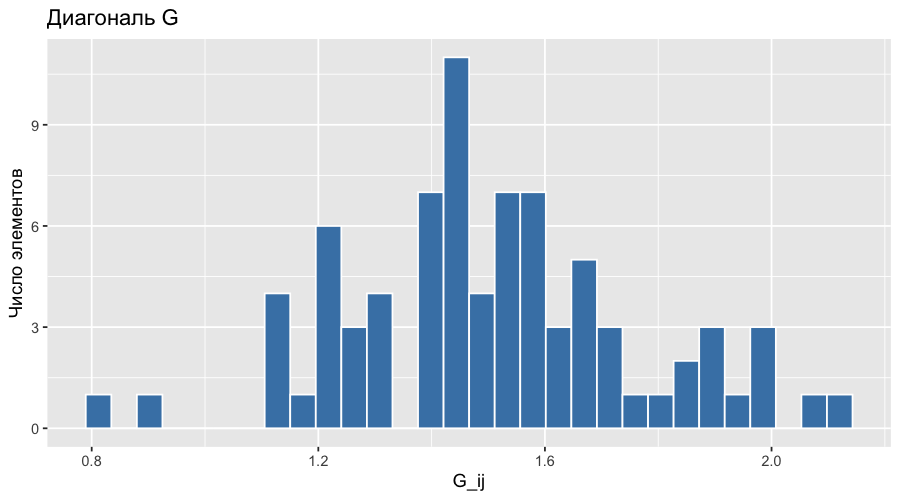

In [21]:
ggplot(data.frame(value = diag(G)), aes(x = value)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  labs(title = "Диагональ G", x = "G_ij", y = "Число элементов")


- А недиагональные элементы показывают, что почти у все животные абсолютно нетипичны.


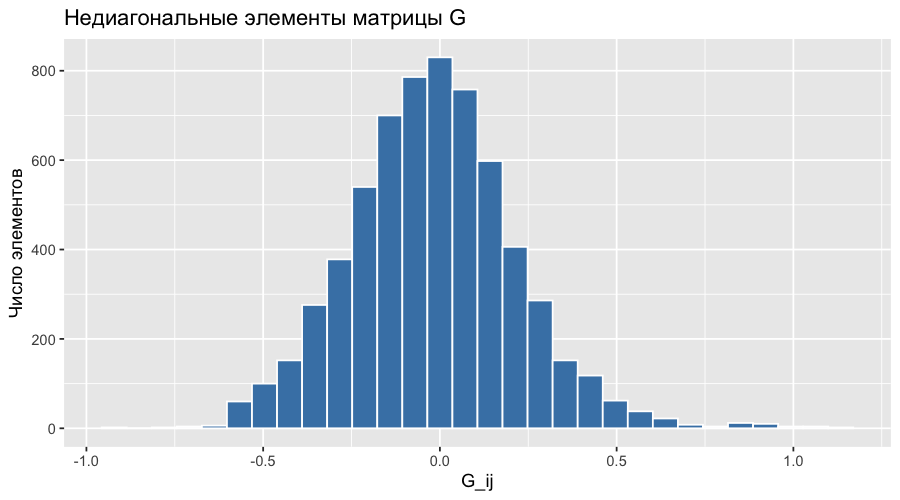

In [22]:
ggplot(data.frame(value = G[row(G) != col(G)]), aes(x = value)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  labs(title = "Недиагональные элементы матрицы G", x = "G_ij", y = "Число элементов")


## 3.3. Построение матрицы H

Итоговая матрица - <u>матрица H</u>.

<u>Матрица H</u> - это объединённая матрица родства, которая совмещает геномную <u>матрицу G</u> для генотипированных животных и <u>матрицу А</u> для животных из родословной. Она использует геномную <u>матрицу G</u> для генотипированных животных и матрицу родословной A для всех остальных.


In [23]:
#common_ids <- intersect(rownames(G), rownames(A))
#A_sub <- A[common_ids, common_ids]
#G_sub <- G[common_ids, common_ids]
#H <- Hmatrix(A = a_standartization(A, G_sub_reg), G = inversing(G, 1e-5))
H <- Hmatrix(A = A, G = inversing(G, 1e-5))


Comparing the matrices... 
Completed! Time = 0  minutes 
Computing the H matrix... 

 Completed! Time = 0.0003166667  minutes 


In [24]:
print(knitr::kable(H[1:5, 1:5], booktabs=TRUE, caption='Матрица H (фрагмент)'))




Table: Матрица H (фрагмент)

|   |        18|         17|         16|         19|          5|
|:--|---------:|----------:|----------:|----------:|----------:|
|18 | 1.0886395|  0.1724945|  0.0205505|  0.0094337|  0.1883556|
|17 | 0.1724945|  0.5571241|  0.0535102| -0.0053090|  0.0834358|
|16 | 0.0205505|  0.0535102|  0.7943283|  0.0505951| -0.0948016|
|19 | 0.0094337| -0.0053090|  0.0505951|  0.9255784| -0.0350119|
|5  | 0.1883556|  0.0834358| -0.0948016| -0.0350119|  0.6033751|


Теперь, когда все матрицы полносью посчитаны, можно производить расчёт оценки племенной ценности

# 4. Расчёт оценки племенной ценности и интерпретация результатов

Расчёт оценки племенной ценности мы будем производить с помощью функции *mmes* из библиотеки *sommer*. 

## 4.1. Синхронизация матрицы H данными фенотипов

Для начала нам необходимо синхронизировать матрицу H с данными фенотипов - вставить строки с ID животных, информация о которых присутствует в данных родословной и генетики


In [25]:
all_ids <- rownames(H)

phenotypes_bl <- phenotypes_bl %>% mutate(animal = factor(animal))

full_data <- data.frame(animal=all_ids) %>%
  left_join(phenotypes_bl, by='animal') %>%
  mutate(animal = factor(animal, levels=rownames(H)))


## 4.2. Расчёт оценки племенной ценности

Для расчёта оценки мы берём:

- значение трейта из данных фенотипов; 

- значения фиксированных эффектов;

- значения случайных эффектов (*random*);

- данные матрицы H (*Gu*);

- ковариация остатков между наблюдениями (*rcov*);

- данные фенотипов, синхронизированные с матрицей H


In [26]:
model <- mmes(
  trait ~ dam_age + sire_age + okot_massa + okot_number + okot_vsego + event_season + event_year,
  random = ~ vsm(ism(animal), Gu = H) + economy,
  rcov = ~ units,
  data = full_data,
  verbose = TRUE
)


Version out of date. Please update sommer to the newest version using:
install.packages('sommer') in a new session
 Use the 'dateWarning' argument to disable the warning message.iteration    LogLik     wall    cpu(sec)   restrained
    1      -94.2884   20:47:53      1           0
    2      -92.1478   20:47:53      1           1
    3      -89.8732   20:47:53      1           1
    4      -89.8467   20:47:53      1           1
    5      -89.8465   20:47:53      1           1
    6      -89.8465   20:47:53      1           1


## 4.3. Расчёт стандартных ошибок (SE) и точности (reliability) оценок племенной ценности

Основным показателем качества полученных оценок племенной ценности является расчёт стандартной ошибки оценкок. В данном случае, стандартные ошибки представляют диагональные элементы матрицы ковариаций


In [27]:
bu <- model$bu[, 1]
names(bu) <- rownames(model$bu)
se_all <- diag(model$Ci)
se_aligned <- if (!is.null(names(se_all))) se_all[names(bu)] else se_all[seq_along(bu)]
solutions <- data.frame(EBV = as.numeric(bu), SE = as.numeric(se_aligned))
rownames(solutions) <- names(bu)
keep <- grepl('^[0-9]+$', rownames(solutions))
solutions <- solutions[keep, , drop = FALSE]


Мы получаем оценки племенной ценности у животных. Теперь посмотрим на их распределение


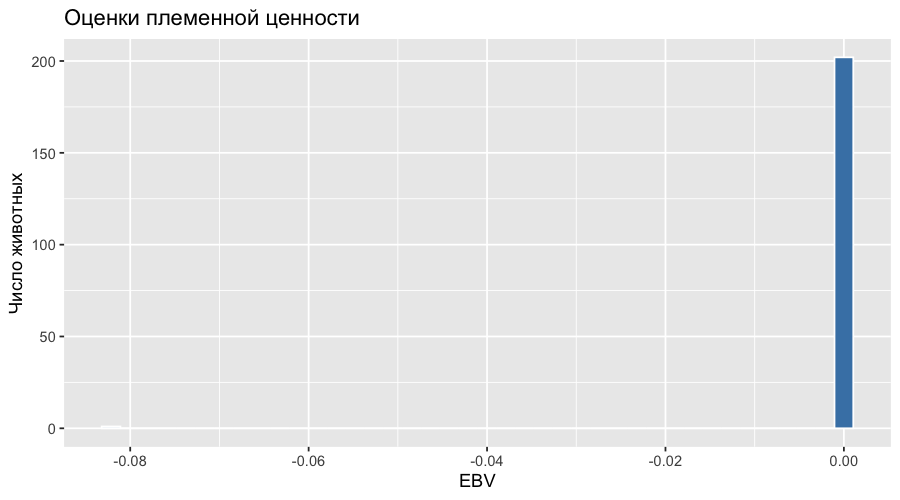

In [28]:
ggplot(solutions, aes(x = EBV)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Оценки племенной ценности", x = "EBV", y = "Число животных")


Также посмотрим распределение стандартной ошибки


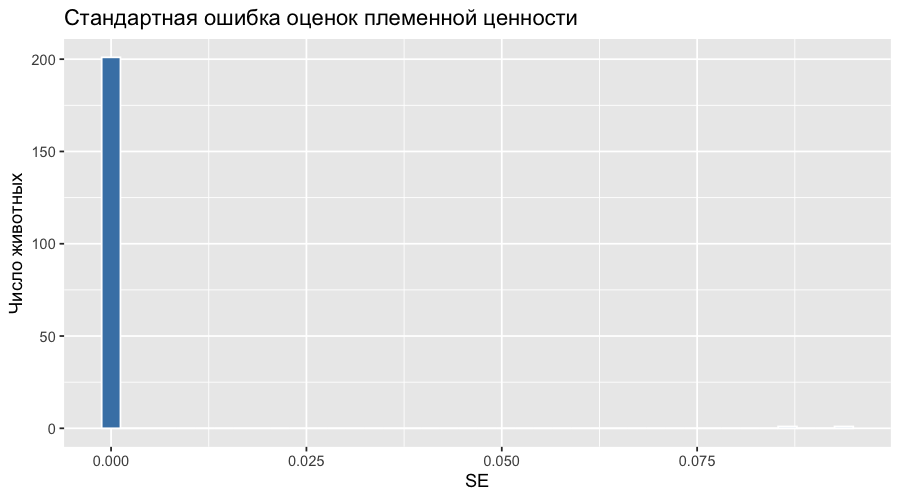

In [29]:
ggplot(solutions, aes(x = SE)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Стандартная ошибка оценок племенной ценности", x = "SE", y = "Число животных")


С показателем точности всё немного сложнее. Вот алгоритм, как мы считаем это показатель:

1. Получаем предиктивные ошибки вариабельности (*PEVs*) для случайных эффектов;

2. Извлекаем оценку дисперсии случайных эффектов;

3. Рассчитываем надёжность оценок, основанныю на PEV и оценках случайной дисперсии;

4. Присваиваем порядковые номера надёжности исходя из общих уровней


In [30]:
pev <- model$uPevList$`vsm(ism(animal), Gu = H)`[, 1]
sigma2_u <- model$theta$`vsm(ism(animal), Gu = H)`[1, 1]
reliability <- 1 - (pev / sigma2_u)
rel_ids <- gsub('[^0-9]', '', names(reliability))
if (!any(nzchar(rel_ids))) {
  rel_ids <- rownames(solutions)[seq_along(reliability)]
}
names(reliability) <- rel_ids
common <- intersect(rownames(solutions), names(reliability))
solutions <- solutions[common, , drop = FALSE]
solutions$reliability <- as.numeric(reliability[common])
id_code <- as.integer(rownames(solutions))
orig <- common_levels[id_code]
rownames(solutions) <- ifelse(is.na(orig), as.character(id_code), orig)


In [31]:
reliability


 18  17  16  19   5 200 198 194  26  24  23  21  20  15  13  12  11  10   7   4 
NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN 
201 199 196 195 193 192 190 188 186 183 182 177 176 174 171  22   9   8   6 197 
NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN 
189 187 185 184 181 179 178 175 173 172 170 168 167 166 165 164 163 162 161 160 
NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN 
159 157 156 155 154 153 152 151 150 149 148 146 145 144 143 142 141 140 139 138 
NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN 
137 135 134 133 132 131 130 129 128 127 126 124 123 122 121 120 119 118 117 116 
NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN 
114 102  91  80  69  58  47  36  25  14   3 191 180 169 158 147 136 125 113   2 
NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN NaN 
  1 115 112 111 110 109 108 

Removed 201 rows containing non-finite outside the scale range (`stat_bin()`).


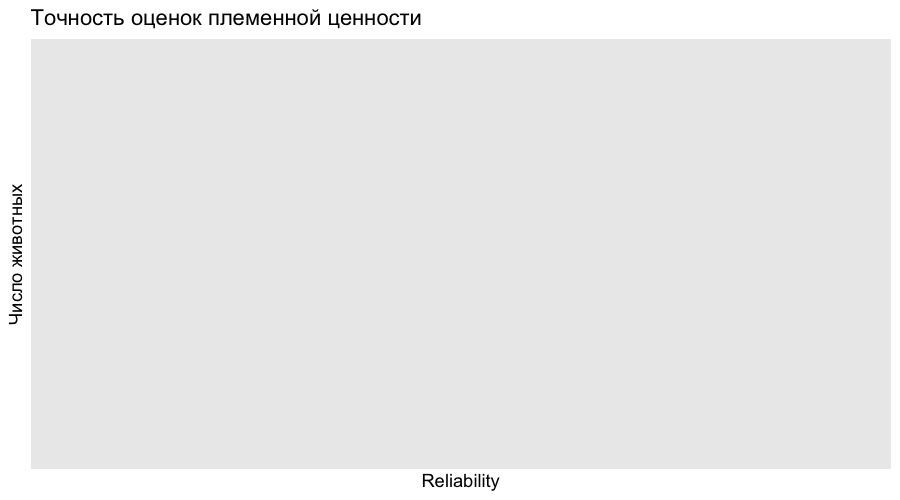

In [32]:
ggplot(solutions, aes(x = reliability)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Точность оценок племенной ценности", x = "Reliability", y = "Число животных")


# 5. Статистический анализ расчёта оценок с использованием R sommer

Также мы сделали наглядное соотношение оценки R и эталона из `data/estimations.csv` (истинная TBV в колонке progenes).


In [33]:
blupf90_solutions <- read.csv('data/estimations.csv')


In [34]:
solutions_complex <- solutions %>%
  mutate(nom_osn = as.character(rownames(.))) %>%
  `rownames<-`(NULL) %>%
  left_join(blupf90_solutions %>% mutate(nom_osn = as.character(nom_osn)), by='nom_osn') %>%
  filter(!is.na(progenes)) %>%
  rename(ebv_r = EBV, rel_r = reliability, ebv_blup = progenes, rel_blup = rel_progenes) %>%
  select(nom_osn, ebv_r, rel_r, ebv_blup, rel_blup)


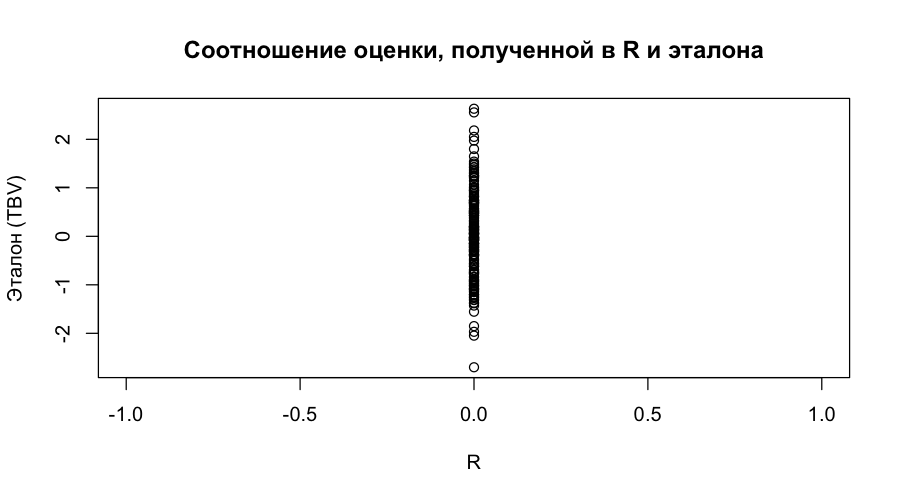

In [35]:
plot(solutions_complex$ebv_r, solutions_complex$ebv_blup, main="Соотношение оценки, полученной в R и эталона", xlab="R", ylab="Эталон (TBV)")


## 5.1. Первичное тестирование Стьюдента

Мы провели AB тестирование c использованием теста Стьюдента, сравнив:

1. Оценки племенной ценности, посчитанные с использованием смешанного ядра и библиотеки *sommer*; 

2. Эталонные значения из сгенерированного датасета

Мы выдвигаем две гипотезы:

- Нулевая гипотеза: результаты оценок, посчитанные двумя способами полностью идентичны;

- Альтернативная гипотеза: результаты оценок, посчитанные двумя способами различаются


In [36]:
t.test(solutions_complex$ebv_r, solutions_complex$ebv_blup, alternative = "two.sided", var.equal = FALSE)



	Welch Two Sample t-test

data:  solutions_complex$ebv_r and solutions_complex$ebv_blup
t = -0.49224, df = 199, p-value = 0.6231
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -0.15250724  0.09157856
sample estimates:
 mean of x  mean of y 
0.00000000 0.03046434 



In [37]:
cor(solutions_complex$ebv_r, solutions_complex$ebv_blup)


the standard deviation is zero


[1] NA


Коэффициент корреляции Пирсона равен **`cor(solutions_complex$ebv_r, solutions_complex$ebv_blup)`**.

## 5.2. Дельта-метод

Мы проводим исследование с помощью дельта-метода и выдвигаем также две гипотезы:

- Нулевая гипотеза: между выборками существует определённое отношение;

- Альтернативная гиапотеза: между выборками нет определённых отношений


In [38]:
delta_method <- function(X, Y) {
  mu_X <- mean(X)
  mu_Y <- mean(Y)
  print(c(mu_X, mu_Y))
  
  sigma_X <- sqrt(var(X))
  sigma_Y <- sqrt(var(Y))
  
  k_hat <- mu_X / mu_Y
  sigma_hat <- sigma_X / sigma_Y 
  
  SE_k <- sqrt((sigma_X**2 * mu_Y**2 + sigma_Y**2 * mu_X**2)/(mu_Y**4)/length(X))
  
  lower_bound <- k_hat - qnorm(0.975) * SE_k
  upper_bound <- k_hat + qnorm(0.975) * SE_k
  return(c(k_hat, sigma_hat, lower_bound, upper_bound))
}


In [39]:
delta <- delta_method(solutions_complex$ebv_r, solutions_complex$ebv_blup)


[1] 0.00000000 0.03046434


На основании результатов дельта-метода отношение средних оценок составляет **`delta[[1]]`** с 95% доверительным интервалом **`paste(delta[[3]], delta[[4]])`**.

# 6. Заключение

В ходе работы была проведена оценка племенной ценности животных методом BLUP c использованием смешанных моделей. В качестве фиксированных эффектов учитывались фенотипические данные, в качестве случайных - генетические эффекты животных с использованием матрицы родства.

Модель позволила скорректировать фенотипические значения с учётом систематических факторов и выделить истинный генетический вклад каждого животного.

Полученные EBV оценки могут быть использованы для отбора и селекции, так как они учитывают как генетическую информацию, так и родословные данные. Таким образом, модель обеспечивает более точную и сбалансированную оценку животных по сравнению с традиционными методами как оценка по срерднему потомству или фенотипу.

Использование смешанной родословно-геномной матрицы H позволило учесть как традиционные, так и геномные источники родства, что повысило точность оценки, особенно для животных без большого количество потомства.


In [40]:
print(knitr::kable(head(solutions, 8), digits = 3, caption = 'EBV, SE и reliability (фрагмент)'))
print(knitr::kable(head(solutions_complex, 8), digits = 3, caption = 'EBV somer и эталон TBV (фрагмент)'))




Table: EBV, SE и reliability (фрагмент)

|    | EBV| SE| reliability|
|:---|---:|--:|-----------:|
|113 |   0|  0|         NaN|
|112 |   0|  0|         NaN|
|111 |   0|  0|         NaN|
|114 |   0|  0|         NaN|
|101 |   0|  0|         NaN|
|98  |   0|  0|         NaN|
|96  |   0|  0|         NaN|
|92  |   0|  0|         NaN|




Table: EBV somer и эталон TBV (фрагмент)

|nom_osn | ebv_r| rel_r| ebv_blup| rel_blup|
|:-------|-----:|-----:|--------:|--------:|
|113     |     0|   NaN|   -0.144|    0.874|
|112     |     0|   NaN|   -0.371|    0.729|
|111     |     0|   NaN|    0.619|    0.618|
|114     |     0|   NaN|   -0.886|    0.530|
|101     |     0|   NaN|   -0.043|    0.959|
|98      |     0|   NaN|   -1.135|    0.468|
|96      |     0|   NaN|    0.906|    0.525|
|92      |     0|   NaN|   -0.061|    0.943|
